<a href="https://colab.research.google.com/github/veniola/DX703-Assignments/blob/main/Homework_07.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 7: Sentiment Classification with Pretrained and Fine-Tuned GloVe Embeddings

#### Due: **Sunday, October 18th** @ 11:59 PM (with 2 hour & 1 minute grace period)

In this homework, we'll continue investigating sentiment classification using **Bag of Embeddings** models and the IMDB movie review dataset.

Previously, we used pretrained GloVe word embeddings that remained fixed during training. This week, we'll explore **fine-tuning**, allowing pretrained embeddings to adapt to the sentiment classification task. We'll also investigate how the vocabulary size, maximum review length, and embedding dimension affect model performance, training time, and generalization.

The homework consists of three problems:

- **Problem 1 — Fine-Tuning and Model Architecture:** Compare frozen and unfrozen GloVe embeddings, then experiment with hidden layers, regularization, and training techniques to improve validation performance.

- **Problem 2 — Vocabulary Size and Review Length:** Using a consistent model architecture and training procedure, investigate how changing the vocabulary size and maximum review length affects classification performance.

- **Problem 3 — Embedding Dimension:** Compare 100-dimensional and 300-dimensional GloVe embeddings to determine whether richer word representations improve generalization.

### Experimental Methodology

Throughout the homework, we'll use a stratified **80/10/10 train/validation/test split** of the IMDB dataset.

Use the training set to fit your models and the validation set to compare experiments. Select preferred configurations using **minimum validation loss** as the primary criterion, and report validation accuracy at the epoch where that minimum loss occurred.

Keep the model architecture and training settings fixed when investigating preprocessing parameters or embedding dimensions. This helps isolate the effects of the parameters being studied.

**Do not use the held-out test set for model selection.** It is reserved for final evaluation.

### Managing Training Time

Training several neural networks can be time-consuming, especially without GPU acceleration. To make experimentation more practical, the notebook provides a `DATA_FRACTION` parameter:

- `DATA_FRACTION = 0.10` for quick debugging.
- `DATA_FRACTION = 0.25` for preliminary experiments.
- `DATA_FRACTION = 1.0` for full training.

This parameter reduces only the training set; the validation and test sets remain unchanged.

**Before submitting your homework, set `DATA_FRACTION = 1.0` and rerun your experiments.** All graded answers must be based on the full training set.

### What You'll Submit

Complete the coding experiments and the graded-answer cells for each problem. Use expressions based on your experimental results rather than manually entering numerical values.

Your goal is not simply to maximize accuracy, but to understand **how different design choices affect generalization, computational cost, and the tradeoffs involved in building a sentiment classifier.**

### Useful Imports

In [1]:
%pip install numpy
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install scikit-learn

import os
import time
from pathlib import Path
from collections import Counter

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

# Mac users experiencing TensorFlow Metal GPU crashes
# can uncomment the following line:

tf.config.set_visible_devices([], "GPU")

from sklearn.model_selection import train_test_split

from tensorflow.keras import Input, Sequential
from tensorflow.keras.layers import (
    Embedding,
    GlobalAveragePooling1D,
    Dense,
    Dropout
)
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Reproducibility
random_seed = 42
tf.keras.utils.set_random_seed(random_seed)

# Utility
def format_hms(seconds):
    return time.strftime("%H:%M:%S", time.gmtime(seconds))

print("Visible GPUs:", tf.config.get_visible_devices("GPU"))

Visible GPUs: []


### Utility: Plotting Learning Curves

The `plot_learning_curves()` function displays two plots for a trained neural network:

- **Loss:** Training and validation binary cross-entropy across epochs.
- **Accuracy:** Training and validation accuracy across epochs.

Both plots mark the epoch at which **validation loss is minimized**. This helps us identify the preferred model checkpoint and examine signs of overfitting or underfitting.

The function is called automatically by `train_and_validate()`, so you won't normally need to call it directly.

In [2]:

def plot_learning_curves(history, title="Learning Curves", show=True):

    h = history.history

    best_idx = int(np.argmin(h["val_loss"]))
    best_epoch = best_idx + 1
    epochs = np.arange(1, len(h["loss"]) + 1)

    fig, axs = plt.subplots(
        2, 1, figsize=(8, 7), sharex=True
    )

    # Loss
    axs[0].plot(epochs, h["loss"], label="Training")
    axs[0].plot(epochs, h["val_loss"], label="Validation")
    axs[0].scatter(
        best_epoch, h["val_loss"][best_idx],
        color="red", marker="x", s=70,
        label=f"Best epoch: {best_epoch}"
    )
    axs[0].set_title(f"{title} — Binary Cross-Entropy")
    axs[0].set_ylabel("Loss")
    axs[0].legend()
    axs[0].grid(True, alpha=0.3)

    # Accuracy
    axs[1].plot(epochs, h["accuracy"], label="Training")
    axs[1].plot(epochs, h["val_accuracy"], label="Validation")
    axs[1].scatter(
        best_epoch, h["val_accuracy"][best_idx],
        color="red", marker="x", s=70,
        label="Accuracy at best epoch"
    )
    axs[1].set_title("Accuracy")
    axs[1].set_xlabel("Epoch")
    axs[1].set_ylabel("Accuracy")
    axs[1].set_ylim(0, 1.05)
    axs[1].legend()
    axs[1].grid(True, alpha=0.3)

    plt.tight_layout()

    if show:
        plt.show()
    else:
        plt.close(fig)

    return best_idx


### Utility: Training and Validation

The `train_and_validate()` function provides a consistent way to train and evaluate models throughout this homework.

- Accepts a model and explicit training and validation datasets.
- Uses the Adam optimizer and binary cross-entropy loss by default.
- Applies early stopping based on validation loss, restoring the weights from the best epoch.
- Supports optional callbacks, learning-rate adjustments, and other training parameters.
- Plots learning curves showing training and validation loss and accuracy.
- Reports the **minimum validation loss**, validation accuracy at that epoch, number of epochs trained, and execution time.
- Returns a dictionary containing the main results for comparing experiments.

**Model selection:** Throughout the homework, we'll use minimum validation loss as our primary criterion, rather than maximum validation accuracy.

**Important:** This function never evaluates the held-out test set, which is reserved for final evaluation.

In [3]:
# Train and Validate

def train_and_validate(
    model,
    X_train, y_train,
    X_val, y_val,
    title="Learning Curves",
    epochs=200,
    optimizer="Adam",
    lr_schedule=1e-3,
    clipnorm=None,
    batch_size=128,
    loss="binary_crossentropy",
    metrics=None,
    use_early_stopping=True,
    patience=10,
    min_delta=0.0001,
    callbacks=None,
    verbose=0,
    plot=True
):

    if metrics is None:
        metrics = ["accuracy"]

    if callbacks is None:
        callbacks = []

    print(f"\n{title}\n")

    if optimizer == "Adam":
        opt = Adam(
            learning_rate=lr_schedule,
            clipnorm=clipnorm
        )
    else:
        opt = optimizer

    model.compile(
        optimizer=opt,
        loss=loss,
        metrics=metrics
    )

    cbs = list(callbacks)

    if use_early_stopping:
        cbs.insert(0, EarlyStopping(
            monitor="val_loss",
            patience=patience,
            min_delta=min_delta,
            restore_best_weights=True,
            verbose=verbose
        ))

    start = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        callbacks=cbs,
        verbose=verbose
    )

    elapsed = time.time() - start

    h = history.history
    best_idx = int(np.argmin(h["val_loss"]))
    best_epoch = best_idx + 1
    num_epochs = len(h["loss"])

    best_val_loss = float(h["val_loss"][best_idx])
    best_val_acc = float(h["val_accuracy"][best_idx])
    train_acc_at_best = float(h["accuracy"][best_idx])

    if plot:
        plot_learning_curves(history, title=title)

    print(f"Epochs Trained:                {num_epochs}")
    print(f"Best Epoch:                    {best_epoch}")
    print(f"Training Accuracy @ Best:      {train_acc_at_best:.4f}")
    print(f"Validation Loss @ Best:        {best_val_loss:.4f}")
    print(f"Validation Accuracy @ Best:    {best_val_acc:.4f}")
    print(f"Execution Time:                {format_hms(elapsed)}")

    return {
            "title": title,
            "best_epoch": best_epoch,
            "epochs_trained": num_epochs,
            "Val Loss @ Best": best_val_loss,
            "Val Acc @ Best": best_val_acc,
            "Execution Seconds": elapsed
        }


### Load and preprocess dataset

Here is where you can set two important preprocessing parameters:

- `training_vocabulary_size`: The maximum number of tokens in the vocabulary. Tokens outside this vocabulary are treated as out-of-vocabulary (OOV).
- `max_text_length`: The maximum number of tokens per review. Longer reviews are truncated, and shorter reviews are padded.

**Note:** The IMDB dataset is originally divided into 50% training and 50% testing. We intentionally recombine these partitions and create a new **stratified 80/10/10 split**:

- **80% training** (40,000 reviews)
- **10% validation** (5,000 reviews)
- **10% testing** (5,000 reviews)

We will use the same split throughout the homework so that experiments with different vocabulary sizes, review lengths, and embedding dimensions can be compared fairly. The test set will be reserved for final evaluation.

In [4]:

# ============================================================
# Load and preprocess the IMDB dataset
# ============================================================

training_vocabulary_size = 50_000       # <-----
max_text_length          = 500          # <-----
DATA_FRACTION            = 0.25         # <----- 1.0 for final submission

assert 0 < DATA_FRACTION <= 1.0

# ------------------------------------------------------------
# 1. Load all reviews without restricting the vocabulary
# ------------------------------------------------------------

(X_tr, y_tr), (X_te, y_te) = imdb.load_data()

X = np.concatenate([X_tr, X_te], axis=0)
y = np.concatenate([y_tr, y_te], axis=0)

# ------------------------------------------------------------
# 2. Stratified 80/10/10 train/validation/test split
# ------------------------------------------------------------

X_train_raw, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.20,
    random_state=random_seed,
    stratify=y
)

X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=random_seed,
    stratify=y_temp
)

# ------------------------------------------------------------
# 3. Training-data throttle
#    Keep validation and test sets unchanged
# ------------------------------------------------------------

if DATA_FRACTION < 1.0:
    X_train_raw, _, y_train, _ = train_test_split(
        X_train_raw,
        y_train,
        train_size=DATA_FRACTION,
        random_state=random_seed,
        stratify=y_train
    )

print(f"DATA_FRACTION:      {DATA_FRACTION}")
print(f"Training reviews:   {len(X_train_raw):,}")
print(f"Validation reviews: {len(X_val_raw):,}")
print(f"Test reviews:       {len(X_test_raw):,}")

# ------------------------------------------------------------
# 4. Apply vocabulary restriction and pad/truncate sequences
#    Preserve the raw sequences for later experiments
# ------------------------------------------------------------

def prepare_sequences(raw_sequences, vocabulary_size, max_length):
    """Apply vocabulary cap, then pad/truncate sequences."""

    capped = [
        [token if token < vocabulary_size else 2
         for token in review]
        for review in raw_sequences
    ]

    return pad_sequences(
        capped,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

X_train = prepare_sequences(
    X_train_raw, training_vocabulary_size, max_text_length
)

X_val = prepare_sequences(
    X_val_raw, training_vocabulary_size, max_text_length
)

X_test = prepare_sequences(
    X_test_raw, training_vocabulary_size, max_text_length
)

print()
print("Training:  ", X_train.shape)
print("Validation:", X_val.shape)
print("Test:      ", X_test.shape)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
DATA_FRACTION:      0.25
Training reviews:   10,000
Validation reviews: 5,000
Test reviews:       5,000

Training:   (10000, 500)
Validation: (5000, 500)
Test:       (5000, 500)


### Prelude: Exploring Review Lengths and Vocabulary Coverage

Before building our models, we'll examine two important characteristics of the IMDB dataset:

- **Review lengths:** How many tokens does a typical review contain? What fraction of reviews would be truncated if we limited each review to 200, 500, or 1,000 tokens?
- **Vocabulary coverage:** What fraction of word occurrences can we represent when we limit the vocabulary to the 5,000, 10,000, or 50,000 most frequent words?

These analyses will help us select reasonable initial values for `max_text_length` and `training_vocabulary_size`.

Both parameters involve tradeoffs. Larger values preserve more information but require more memory and computation. More information does not necessarily translate into better classification accuracy.

We'll use these observations to guide our experiments later in the homework.

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total unique words in Keras IMDB word_index (corpus-wide): 88,584

Number of training reviews: 10,000
Max length: 2,494 tokens
Mean length: 232.2 tokens
Median length: 175 tokens
90th percentile: 453 tokens
95th percentile: 592 tokens
99th percentile: 883 tokens


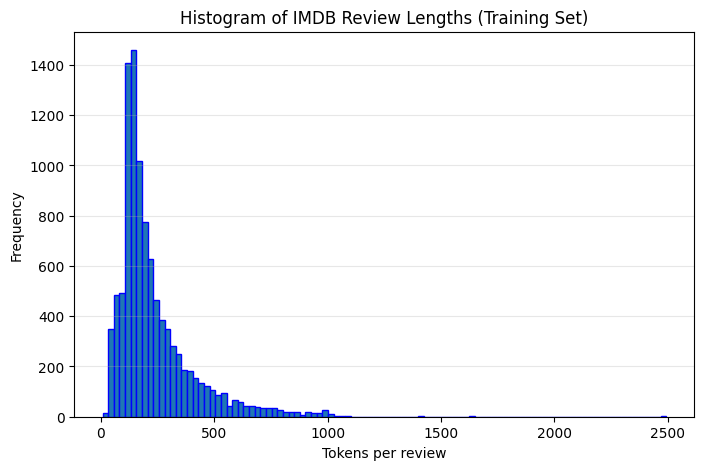


Unique word types in TRAIN: 50,160
Total word tokens in TRAIN: 2,312,201

Coverage metrics by candidate vocabulary size (TRAIN split):
training_vocabulary_size=  2,000 | coverage= 83.27% | OOV= 16.73% | types kept=  1,996 | tokens kept= 1,925,441
training_vocabulary_size=  5,000 | coverage= 90.42% | OOV=  9.58% | types kept=  4,996 | tokens kept= 2,090,775
training_vocabulary_size= 10,000 | coverage= 94.54% | OOV=  5.46% | types kept=  9,993 | tokens kept= 2,185,857
training_vocabulary_size= 20,000 | coverage= 97.40% | OOV=  2.60% | types kept= 19,724 | tokens kept= 2,252,126
training_vocabulary_size= 30,000 | coverage= 98.52% | OOV=  1.48% | types kept= 28,195 | tokens kept= 2,277,977
training_vocabulary_size= 50,000 | coverage= 99.41% | OOV=  0.59% | types kept= 39,431 | tokens kept= 2,298,673
training_vocabulary_size= 70,000 | coverage= 99.74% | OOV=  0.26% | types kept= 45,174 | tokens kept= 2,306,128
training_vocabulary_size= 88,588 | coverage=100.00% | OOV=  0.00% | types kept= 

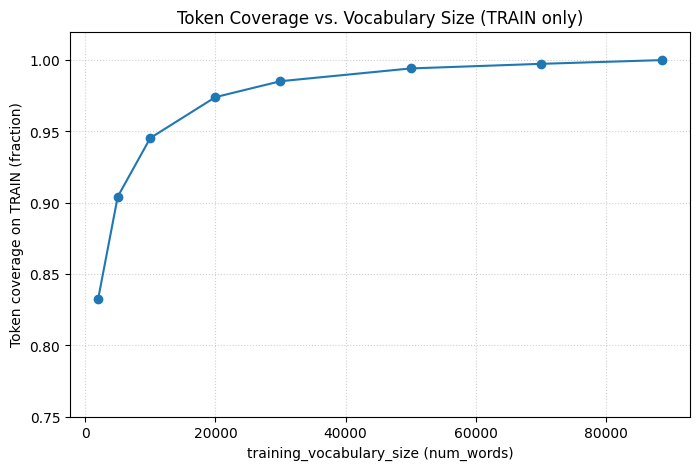

In [5]:

# ============================================================
# IMDB EDA: Review lengths and vocabulary coverage
# ============================================================

from collections import Counter
import numpy as np
import matplotlib.pyplot as plt

# Assumes X_train contains the original, unpadded sequences
# with no vocabulary cap applied.

# ------------------------------------------------------------
# 1. Global vocabulary statistics
# ------------------------------------------------------------

word_index = imdb.get_word_index()
total_unique_words_corpus = len(word_index)

print(f"Total unique words in Keras IMDB word_index "
      f"(corpus-wide): {total_unique_words_corpus:,}")

# ------------------------------------------------------------
# 2. Review length statistics
# ------------------------------------------------------------

lengths = np.fromiter(
    (len(review) for review in X_train_raw),
    dtype=np.int32
)

print(f"\nNumber of training reviews: {len(lengths):,}")
print(f"Max length: {lengths.max():,} tokens")
print(f"Mean length: {lengths.mean():.1f} tokens")
print(f"Median length: {np.median(lengths):.0f} tokens")

for q in (90, 95, 99):
    print(f"{q}th percentile: "
          f"{int(np.percentile(lengths, q))} tokens")

plt.figure(figsize=(8, 5))
plt.hist(lengths, bins=100, edgecolor="blue")
plt.title("Histogram of IMDB Review Lengths (Training Set)")
plt.xlabel("Tokens per review")
plt.ylabel("Frequency")
plt.grid(axis="y", alpha=0.3)
plt.show()

# ------------------------------------------------------------
# 3. Token frequency counts (training data only)
#
# IMDB token IDs:
#   0 = PAD
#   1 = START
#   2 = OOV
#   3 = UNUSED
#   4+ = actual words
# ------------------------------------------------------------

train_counts = Counter(
    token
    for review in X_train_raw
    for token in review
    if token >= 4
)

total_tokens_train_words = sum(train_counts.values())
num_unique_words_train = len(train_counts)

print(f"\nUnique word types in TRAIN: "
      f"{num_unique_words_train:,}")
print(f"Total word tokens in TRAIN: "
      f"{total_tokens_train_words:,}")

# ------------------------------------------------------------
# 4. Calculate vocabulary coverage
#
# Keras assigns lower token IDs to more frequent words
# in the original IMDB vocabulary.
#
# A vocabulary cap K retains word IDs below K.
# All remaining word IDs become OOV.
# ------------------------------------------------------------

def coverage_for_cap(num_words_cap):

    kept_types = sum(
        token < num_words_cap
        for token in train_counts
    )

    kept_tokens = sum(
        count
        for token, count in train_counts.items()
        if token < num_words_cap
    )

    oov_tokens = total_tokens_train_words - kept_tokens

    coverage = kept_tokens / total_tokens_train_words
    oov_share = oov_tokens / total_tokens_train_words

    return {
        "cap": num_words_cap,
        "kept_tokens": kept_tokens,
        "kept_types": kept_types,
        "coverage": coverage,
        "oov_share": oov_share
    }

# ------------------------------------------------------------
# 5. Vocabulary coverage table
# ------------------------------------------------------------

candidate_caps = [
    2_000, 5_000, 10_000, 20_000,
    30_000, 50_000, 70_000, 88_588
]

rows = [coverage_for_cap(k) for k in candidate_caps]

print("\nCoverage metrics by candidate vocabulary size "
      "(TRAIN split):")

for r in rows:
    print(
        f"training_vocabulary_size={r['cap']:>7,} | "
        f"coverage={r['coverage']*100:6.2f}% | "
        f"OOV={r['oov_share']*100:6.2f}% | "
        f"types kept={r['kept_types']:>7,} | "
        f"tokens kept={r['kept_tokens']:>10,}"
    )

# ------------------------------------------------------------
# 6. Vocabulary coverage plot
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    candidate_caps,
    [r["coverage"] for r in rows],
    marker="o"
)

plt.xlabel("training_vocabulary_size (num_words)")
plt.ylabel("Token coverage on TRAIN (fraction)")
plt.title("Token Coverage vs. Vocabulary Size (TRAIN only)")
plt.grid(True, linestyle=":", alpha=0.6)
plt.ylim(0.75, 1.02)
plt.show()


### Download the GloVe Word Embeddings

For this assignment, we will use pretrained GloVe word embeddings. Because the file is large, you will download it separately.

1. [Download glove.6B.zip from Google Drive](https://drive.google.com/file/d/1glSg-KsKNt1E1BMJLOYtJXZ7loz4XTZ_/view).
2. Move the downloaded ZIP file into the same folder as this notebook.
3. Extract the ZIP file into a folder named `glove.6B`. This folder should contain two files:
   - `glove.6B.100d.txt`
   - `glove.6B.300d.txt`

Your directory structure should look like this:

```text
Homework_07.ipynb
glove.6B/
    glove.6B.100d.txt
    glove.6B.300d.txt
```

Make sure the `glove.6B` folder is in the same directory as your notebook before continuing.

### Build the embedding matrix

Next, we'll construct an embedding matrix using pretrained GloVe word vectors.

Here you can set:

- `embedding_dimension`: The number of values used to represent each word. The GloVe 6B dataset provides embeddings of 50, 100, 200, and 300 dimensions.

The code loads the corresponding GloVe vectors and matches them to the words in our IMDB vocabulary. Words without a matching GloVe vector are initialized with zeros.

We'll begin with **100-dimensional embeddings** and investigate the effect of changing this parameter later in the homework.

The code also reports **GloVe coverage**: the percentage of vocabulary words for which pretrained embeddings are available. This differs from the token coverage examined in our earlier EDA.

In [8]:
# Download and extract the GloVe 6B embeddings directly to Colab
!wget http://nlp.stanford.edu/data/glove.6B.zip
!mkdir -p glove.6B
!unzip -q glove.6B.zip -d glove.6B
# Clean up zip file to save disk space
!rm glove.6B.zip
print("GloVe embeddings downloaded and extracted successfully!")

--2026-10-16 17:09:58--  http://nlp.stanford.edu/data/glove.6B.zip
Resolving nlp.stanford.edu (nlp.stanford.edu)... 171.64.67.140
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:80... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://nlp.stanford.edu/data/glove.6B.zip [following]
--2026-10-16 17:09:58--  https://nlp.stanford.edu/data/glove.6B.zip
Connecting to nlp.stanford.edu (nlp.stanford.edu)|171.64.67.140|:443... connected.
HTTP request sent, awaiting response... 301 Moved Permanently
Location: https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip [following]
--2026-10-16 17:09:58--  https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip
Resolving downloads.cs.stanford.edu (downloads.cs.stanford.edu)... 171.64.64.22
Connecting to downloads.cs.stanford.edu (downloads.cs.stanford.edu)|171.64.64.22|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 862182613 (822M) [application/zip]
Saving to: ‘glove.6B.zip’

glov

In [9]:

# ============================================================
# Build GloVe embedding matrix
# ============================================================

embedding_dimension = 100                 # <-----

word_index = imdb.get_word_index()

# GloVe 6B provides 50, 100, 200, and 300 dimensions
assert embedding_dimension in (50, 100, 200, 300)

glove_path = Path(
    f"glove.6B/glove.6B.{embedding_dimension}d.txt"
)

if not glove_path.exists():
    raise FileNotFoundError(f"GloVe file not found: {glove_path}")

# ------------------------------------------------------------
# Load pretrained GloVe vectors
# ------------------------------------------------------------

embeddings_index = {}

with glove_path.open(encoding="utf8") as f:
    for line in f:
        word, *vec = line.split()
        embeddings_index[word] = np.asarray(
            vec, dtype="float32"
        )

print(f"Loaded {len(embeddings_index):,} GloVe vectors "
      f"of dimension {embedding_dimension}")

# ------------------------------------------------------------
# Construct embedding matrix
# ------------------------------------------------------------

embedding_matrix = np.zeros(
    (training_vocabulary_size, embedding_dimension),
    dtype="float32"
)

matched = 0
total_words = 0

for word, raw_idx in word_index.items():

    idx = raw_idx + 3  # Keras IMDB reserved-token offset

    if idx < training_vocabulary_size:
        total_words += 1

        vec = embeddings_index.get(word)

        if vec is not None:
            embedding_matrix[idx] = vec
            matched += 1

# ------------------------------------------------------------
# Report embedding coverage
# ------------------------------------------------------------

print(f"Embedding matrix shape: {embedding_matrix.shape}")
print(f"Vocabulary words:       {total_words:,}")
print(f"Words found in GloVe:   {matched:,}")
print(f"Words missing in GloVe: {total_words - matched:,}")
print(f"GloVe word coverage:    {matched / total_words:.2%}")


Loaded 400,000 GloVe vectors of dimension 100
Embedding matrix shape: (50000, 100)
Vocabulary words:       49,996
Words found in GloVe:   42,330
Words missing in GloVe: 7,666
GloVe word coverage:    84.67%


### Baseline Model: Frozen GloVe Embeddings

We'll begin by reproducing the baseline model from the coding notebook, using pretrained GloVe embeddings with `trainable=False`.

The model averages the word embeddings for each review and uses a sigmoid output layer for binary sentiment classification. Because the embeddings are frozen, **only the output layer is trained**.

This gives us a reference point for evaluating the benefits of fine-tuning the embeddings in Problem 1.


Baseline — Frozen GloVe



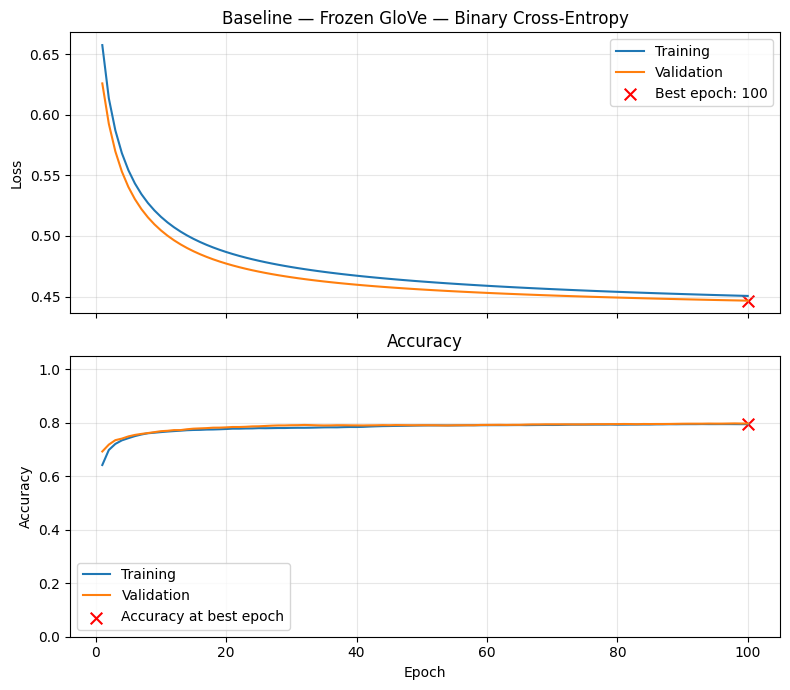

Epochs Trained:                100
Best Epoch:                    100
Training Accuracy @ Best:      0.7940
Validation Loss @ Best:        0.4467
Validation Accuracy @ Best:    0.7964
Execution Time:                00:04:09


In [10]:

# ==================================================
# Baseline: Frozen GloVe Embeddings
# ==================================================

model_baseline_frozen = Sequential([
    Input(shape=(max_text_length,), dtype="int32"),

    Embedding(
        input_dim=training_vocabulary_size,
        output_dim=embedding_dimension,
        weights=[embedding_matrix],
        mask_zero=True,          # Exclude padding from pooling
        trainable=False          # Freeze pretrained embeddings
    ),

    GlobalAveragePooling1D(),    # Average word embeddings
    Dense(1, activation="sigmoid")
])

frozen_results = train_and_validate(
    model_baseline_frozen,
    X_train, y_train,
    X_val, y_val,
    epochs = 100,
    lr_schedule=1e-2,
    title="Baseline — Frozen GloVe"
)


## Problem 1: Fine-Tuning Pretrained GloVe Embeddings

In the baseline model, we used pretrained GloVe embeddings with `trainable=False`, so the embeddings remained fixed while the output layer was trained.

In this problem, we'll investigate **fine-tuning**: allowing the embedding vectors themselves to change during training so that they can adapt to the IMDB sentiment classification task.

### Part A: Establish an Unfrozen Baseline

1. Rebuild the frozen baseline model, changing `trainable=False` to `trainable=True`.
2. Train the model using `train_and_validate()`. Start with a learning rate of `1e-4`, since fine-tuning pretrained embeddings generally requires smaller weight updates.
3. Compare its learning curves and validation performance with the frozen baseline.

Consider how much performance improves when the embeddings are allowed to adapt to the classification task. Does the unfrozen model show evidence of overfitting?

### Part B: Improve the Model

Run **2–3 additional experiments** to investigate whether you can improve the unfrozen baseline.

Consider some of the following modifications:

- Add a hidden `Dense` layer between `GlobalAveragePooling1D` and the output layer, experimenting with its width and activation.
- Introduce L2 regularization and/or dropout to control overfitting.
- Adjust the learning rate or use `ReduceLROnPlateau` to improve convergence.

> Make your changes systematically. For example, first investigate the effect of adding a hidden layer, then experiment with regularization and training adjustments. Compare the learning curves and validation results for each experiment, noting whether your changes improve generalization or reduce overfitting.

### Part C: Select Your Preferred Model

Compare your experiments and select the configuration with the best validation performance, using **minimum validation loss** as your primary criterion.

Record the architecture and training settings of your preferred model.

### Problem 1: Graded Answers

After completing your experiments and selecting your preferred model, assign the following variables:

- **`a1a`**: Minimum validation loss achieved by the unfrozen baseline model in Part A.
- **`a1b`**: Minimum validation loss achieved by your preferred model in Part C (including the unfrozen baseline among the candidates).
- **`a1c`**: Validation accuracy at the epoch of minimum validation loss for your preferred model.

Use expressions based on your experimental results rather than manually entering numerical values.

Print each answer using the standard graded-answer format.

**Note:** Use only training and validation data throughout these experiments. The held-out test set will be reserved for final evaluation.


Baseline — Unfrozen GloVe



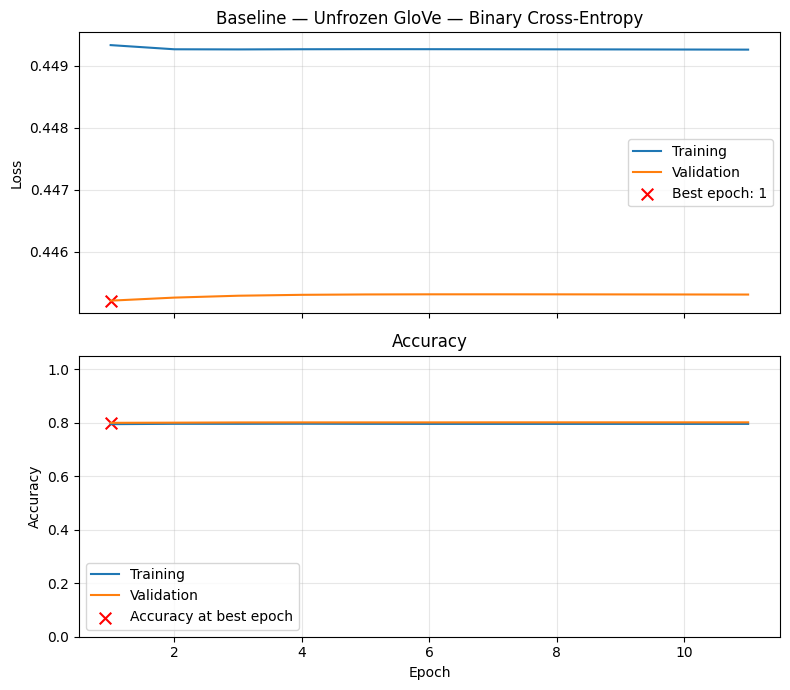

Epochs Trained:                11
Best Epoch:                    1
Training Accuracy @ Best:      0.7940
Validation Loss @ Best:        0.4452
Validation Accuracy @ Best:    0.7990
Execution Time:                00:00:37


In [12]:
# ====================================================
# Problem 1: Fine-Tuning Pretrained GloVe Embeddings
# ====================================================
# -------------------------------------------
# Part A: Establish an Baseline (+ unfrozen)
# -------------------------------------------
# Build model
model_baseline_frozen_1A = Sequential([
    Input(shape=(max_text_length,), dtype="int32"),

    Embedding(
        input_dim=training_vocabulary_size,
        output_dim=embedding_dimension,
        weights=[embedding_matrix],
        mask_zero=True,          # exclude padding from pooling
        trainable=True          # unfreeze pretrained embeddings
    ),

    GlobalAveragePooling1D(),    # average word embeddings
    Dense(1, activation="sigmoid")
])

# Train model
unfrozen_results_1A = train_and_validate(
    model_baseline_frozen,
    X_train, y_train,
    X_val, y_val,
    epochs = 100,
    lr_schedule=1e-4,         # change lr from 1e-2 to 1e-4
    title="1A-Baseline — Unfrozen GloVe"
)

In [14]:
# ====================================================
# Problem 1: Fine-Tuning Pretrained GloVe Embeddings
# ====================================================
# ----------------------------------------------
# Part B-1: Improve the Model (+ unfrozen, hidden dense layer)
# ----------------------------------------------
# Build model
model_baseline_unfrozen_1B1 = Sequential([
    Input(shape=(max_text_length,), dtype="int32"),

    Embedding(
        input_dim=training_vocabulary_size,
        output_dim=embedding_dimension,
        weights=[embedding_matrix],
        mask_zero=True,          # exclude padding from pooling
        trainable=True          # unfreeze pretrained embeddings
    ),

    GlobalAveragePooling1D(),    # average word embeddings
    Dense(64, activation="relu"),   # added hidden dense layer
    Dense(1, activation="sigmoid")
])

# Train model
results_1B1 = train_and_validate(
    model_baseline_unfrozen_1B1,
    X_train, y_train,
    X_val, y_val,
    epochs=100,
    lr_schedule=1e-4,
    title="1B-1 — Unfrozen GloVe (+ unfrozen, hidden dense layer)"
)


# --------------------------------------------------------------
# Part B-2: Improve the Model (+ hidden dense layer, L2 Lambda=1e-4)
# --------------------------------------------------------------
# Build model
model_baseline_unfrozen_1B2 = Sequential([
    Input(shape=(max_text_length,), dtype="int32"),

    Embedding(
        input_dim=training_vocabulary_size,
        output_dim=embedding_dimension,
        weights=[embedding_matrix],
        mask_zero=True,          # exclude padding from pooling
        trainable=True          # unfreeze pretrained embeddings
    ),

    GlobalAveragePooling1D(),    # average word embeddings
    Dense(64, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-4)),
    Dense(1, activation="sigmoid")
])

# Train model
results_1B2 = train_and_validate(
    model_baseline_unfrozen_1B2,
    X_train, y_train,
    X_val, y_val,
    epochs=100,
    lr_schedule=1e-4,
    title="1B-2 — Unfrozen GloVe (+ unfrozen, hidden dense layer, L2 Lambda=1e-4)"
)


1B1 — Unfrozen GloVe (+ hidden dense layer)



KeyboardInterrupt: 

In [ ]:
# ====================================================
# Problem 1: Fine-Tuning Pretrained GloVe Embeddings
# ====================================================
# ----------------------------------------------
# Part C: Select Your Preferred Model (+ )
# ----------------------------------------------
# Build model

### Graded Questions


In [ ]:
# Set a1a to the minimum validation loss achieved by the unfrozen baseline model in Part A.

a1a = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1a = {a1a:.4f}')

a1a = 0.0000


In [ ]:
# Set a1b to the minimum validation loss achieved by your preferred model in Part C
#      (including the unfrozen baseline among the candidates).

a1b = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1b = {a1b:.4f}')

a1b = 0.0000


In [ ]:
# Set a1c to the validation accuracy at the epoch of minimum validation loss for your preferred model.

a1c = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a1c = {a1c:.4f}')

a1c = 0.0000


## Problem 2: Exploring Vocabulary Size and Maximum Review Length

In Problem 1, we investigated how fine-tuning pretrained GloVe embeddings and modifying the classifier architecture affect sentiment classification.

In Problems 2 and 3, we'll turn our attention to the **representation of the input text**. To make meaningful comparisons, we'll use the same model architecture and training settings throughout these experiments:

- Trainable (`trainable=True`) GloVe embeddings
- `GlobalAveragePooling1D`
- A hidden `Dense(64, activation="relu")` layer
- A sigmoid output layer
- Adam optimizer with learning rate `1e-4`
- Early stopping with patience 10
- No additional regularization or learning-rate scheduling

This allows us to investigate the effects of preprocessing and embedding dimension without also changing the model architecture or training procedure.

In this problem, we'll investigate two important preprocessing parameters:

- `training_vocabulary_size`: The maximum number of words represented in the vocabulary.
- `max_text_length`: The maximum number of tokens retained from each review.

Increasing these values gives the model access to more information, but also increases memory requirements and potentially training time. **More information does not necessarily produce better predictions.**

Use the review-length statistics and vocabulary-coverage analysis from the Prelude to guide your experiments.

### Part A: Investigate Vocabulary Size

Start with the standard architecture described above, using a vocabulary size of 50,000, a maximum review length of 500, and an embedding dimension of 100.

Choose a different value for `training_vocabulary_size` and train a new model, keeping `max_text_length = 500` and `embedding_dimension = 100`.

Compare its learning curves and validation performance with the standard configuration. Does increasing or decreasing vocabulary size make a meaningful difference?

### Part B: Investigate Maximum Review Length

Return to the original vocabulary size of 50,000 words.

Choose a different value for `max_text_length` and train another model, keeping `embedding_dimension = 100`.

Consider the review-length distribution from the Prelude when selecting your value.

Compare validation performance and training time. Does retaining more (or less) of each review improve generalization?

### Part C: Combine Your Findings

Run one final experiment using a promising combination of vocabulary size and maximum review length, based on the results of Parts A and B.

You should now have three new experiments, in addition to the standard configuration.

Compare all four configurations, using **minimum validation loss** as your primary criterion. Select your preferred vocabulary size and maximum review length for use in Problem 3.

### Important Guidelines

- Use the same model architecture and training settings for all comparisons.
- Keep the embedding dimension fixed at 100.
- Use the same training and validation reviews throughout.
- Rebuild the embedding matrix when changing vocabulary size.
- Construct and initialize a fresh model for each experiment.
- Use only training and validation performance for model selection. The held-out test set remains untouched until final evaluation.

### Problem 2: Graded Answers

After completing your three experiments, assign the following variables using the results of your experiments.

- **`a2a`**: The minimum validation loss achieved in Part A (vocabulary-size experiment).
- **`a2b`**: The minimum validation loss achieved in Part B (review-length experiment).
- **`a2c`**: The minimum validation loss achieved in Part C (combined experiment).
- **`a2d`**: The vocabulary size of your preferred configuration after comparing all four experiments, including the standard 50,000-word, 500-token reference configuration.
- **`a2e`**: The maximum review length of your preferred configuration.

Use expressions based on your experimental results rather than manually entering the numerical answers. Print each variable using the standard graded-answer format.

In [ ]:
# Your code here; add as many cells as you wish



### Graded Questions

In [ ]:
# Set a2a to the minimum validation loss achieved in Part A

a2a = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2a = {a2a:.4f}')

a2a = 0.0000


In [ ]:
# Set a2b to the minimum validation loss achieved in Part B

a2b = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2b = {a2b:.4f}')

a2b = 0.0000


In [ ]:
# Set a2c to the minimum validation loss achieved in Part C

a2c = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2c = {a2c:.4f}')

a2c = 0.0000


In [ ]:
# Set a2d to the vocabulary size of your preferred configuration after comparing all four models,

a2d = 0             # Replace 0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2d = {a2d}')

a2d = 0


In [ ]:
# Set a2e to the maximum review length of your preferred configuration.

a2e = 0             # Replace with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a2e = {a2e}')

a2e = 0


## Problem 3: Exploring Embedding Dimension

In the previous problems, we investigated fine-tuning pretrained GloVe embeddings and changing the vocabulary size and maximum review length.

Now we'll examine a final parameter: **embedding dimension**, the number of values used to represent each word.

Larger embeddings can represent more complex relationships between words, but they also increase the number of trainable parameters and the computational cost. Does increasing the embedding dimension improve sentiment classification?

### Part A: Compare Embedding Dimensions

1. Start with your preferred model configuration from Problem 2, which uses 100-dimensional GloVe embeddings.
2. Rebuild the embedding matrix using **300-dimensional GloVe embeddings**, and train a fresh model.
3. Keep the vocabulary size, maximum review length, architecture, and training settings unchanged.
4. Compare the two models using minimum validation loss, validation accuracy, training time, and number of trainable parameters.

**Optional:** Repeat the experiment using 50-dimensional or 200-dimensional GloVe embeddings.

### Part B: Select Your Preferred Model

Compare the 100-dimensional and 300-dimensional configurations.

Does the larger embedding dimension improve generalization? Is any improvement substantial enough to justify the additional parameters and training time?

Select your preferred configuration, using **minimum validation loss** as the primary criterion.

### Problem 3: Graded Answers

Assign the following variables using expressions based on your experimental results:

- **`a3a`**: Minimum validation loss achieved with 300-dimensional embeddings.
- **`a3b`**: Validation accuracy at the epoch of minimum validation loss for the 300-dimensional model.
- **`a3c`**: Number of trainable parameters in the 300-dimensional model.
- **`a3d`**: Preferred embedding dimension (100 or 300), based on minimum validation loss.

Print each answer using the standard graded-answer format.

**Important:** Use only training and validation data for model selection. Do not evaluate on the held-out test set.

In [ ]:
# Your code here; add as many cells as you wish



### Graded Questions

In [ ]:
# Set a3a to the minimum validation loss achieved with 300-dimensional embeddings.

a3a = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3a = {a3a:.4f}')

a3a = 0.0000


In [ ]:
# Set a3b to the minimum validation loss achieved with 300-dimensional embeddings.

a3b = 0.0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3b = {a3b:.4f}')

a3b = 0.0000


In [ ]:
# Set a3c to the number of trainable parameters in the 300-dimensional model.

a3c = 0             # Replace 0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3c = {a3c}')

a3c = 0


In [ ]:
# Set a3d to the preferred embedding dimension (100 or 300), based on minimum validation loss.

a3d = 0             # Replace 0.0 with your answer

In [ ]:
# Graded Answer
# DO NOT change this cell in any way

print(f'a3d = {a3d}')

a3d = 0
